# 10.2 · Hybrid search

**Owner:** Member 5 · **Branch:** `dev-hybrid` · **Code:** `src/discovery/rank/hybrid.py` → class `HybridRanker` · **Writes to:** `eval/results/hybrid.json`

**What it means:** Ask BM25 and semantic search for their top 100 each, then combine. **Weighted fusion** rescales both score lists to 0–1 and adds them with a weight α. **Reciprocal Rank Fusion (RRF)** ignores scores and adds 1 / (c + rank) from each list.

**Key idea:** BM25 is precise on exact words, semantic search on meaning; a repository both agree on is usually the right one. RRF needs no score rescaling, which is why it is hard to beat. Depends on Members 3 and 4: agree the interface with them early.

Full guide with starter code, and the Results sheet: [team plan](https://claude.ai/artifact/Rst8GHxAbeHavg4JS2RZV3) (tab 10.2 Hybrid search). Handoff and setup: `docs/handoff-methods.md`.

### Settings to try
| Setting | Values | Why |
|---|---|---|
| α (weighted) | 0.2, 0.4, 0.5, 0.6, 0.8 | Weight of BM25; 1 − α goes to semantic. |
| c (RRF) | 10, 60 | Larger c flattens the difference between rank 1 and rank 10. |
| depth | 50, 100 | How many results to take from each method before fusing. |

**Fixed:** inputs are the BM25Ranker and EmbeddingRanker objects through the shared interface; until they are ready, use rank-bm25 and a quick MiniLM over name + description as stand-ins

### What we agreed (same for all five)
- **One tokenizer:** `tokenize()` from `discovery.preprocess.text`, for documents *and* queries. Never a private one.
- **One interface:** your class extends `SearchMethod` (`src/discovery/rank/base.py`): `fit(corpus)` → self, `search(query, k)` → `[{"doc_id": full_name, "score": float}]`, best first. `check_hits()` checks it.
- **Tune on the 5 development queries only** (`DEV`, replaced by the real ones in Phase 13). The 20 test queries are for the final number only.
- **Seed 42**, paths from `PATHS`, and don't edit the shared files (`rank/base.py`, `rank/devkit.py`, `preprocess/text.py`, `config/config.yaml`) on your branch: ask Member 6.
- Commit this notebook **with its outputs** on `dev-hybrid`. No data files in git.

## 1. Setup: load the corpus and the shared tokenizer

**Check:** it prints 8,223 repositories, and `node.js` and `c#` come out of `tokenize()` in one piece.

In [1]:
%load_ext autoreload
%autoreload 2

import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from discovery.config import PATHS, SEED, set_seed
from discovery.preprocess.text import doc_text, tokenize      # the ONE shared tokenizer (Phase 6)
from discovery.rank.base import check_hits
from discovery.rank.devkit import DEV, load_corpus, measure, save_results, show_top
from discovery.rank.hybrid import HybridRanker

set_seed()
corpus = load_corpus()                                   # data/processed/corpus.parquet
ids = corpus["full_name"].tolist()                       # doc_id = full_name, "owner/name"
text = doc_text(corpus).tolist()                         # name + description + topics + README
print(f"{len(corpus):,} repositories |", tokenize("Built with Node.js and C#"))
print("development queries:", *DEV, sep="\n  ")

8,223 repositories | ['built', 'node.js', 'c#']
development queries:
  beginner inventory management system nestjs postgresql
  point of sale app with react
  school management system laravel
  hotel booking system spring boot
  simple chat application flutter firebase


## 2. Build: Hybrid search

Hybrid has nothing of its own to build: it reuses the two other methods through `search()`.

**Check:** it runs once on the whole corpus without errors. Write down how long it took: it goes in the sheet.

<details><summary>Starter code from the team plan (open it if you are stuck; adapt it, don't just paste)</summary>

```python
from collections import defaultdict

# Members 3 and 4's classes. Until they are in src/, wrap rank_bm25.BM25Okapi and a quick MiniLM
# over name + description in the same search() interface: swapping later is one line.
from discovery.rank.bm25 import BM25Ranker
from discovery.rank.embeddings import EmbeddingRanker
bm25 = BM25Ranker().fit(corpus)
semantic = EmbeddingRanker().fit(corpus)

def minmax(hits):
    if not hits: return {}
    s = [h["score"] for h in hits]; lo, hi = min(s), max(s)
    return {h["doc_id"]: (h["score"] - lo) / (hi - lo) if hi > lo else 1.0 for h in hits}
```
</details>

In [2]:
# Fit the two components ONCE (the semantic one embeds 8,223 repositories: minutes on a CPU).
# Every hybrid setting below reuses them through HybridRanker(..., refit=False) / with_params().
from discovery.rank.bm25 import BM25Ranker            # Member 3, k1=1.5, b=0.75 (eval/results/bm25.json)
from discovery.rank.embeddings import EmbeddingRanker # Member 4, MiniLM + README excerpt (semantic.json)

t = time.perf_counter(); bm25 = BM25Ranker().fit(corpus); t_bm25 = time.perf_counter() - t
t = time.perf_counter(); semantic = EmbeddingRanker().fit(corpus); t_sem = time.perf_counter() - t
print(f"BM25 fit {t_bm25:.1f} s | semantic fit {t_sem:.1f} s | hybrid adds nothing of its own")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BM25 fit 18.5 s | semantic fit 259.5 s | hybrid adds nothing of its own


## 3. Search: a free-text query in, a ranked list out

Two fusion rules. A repository missing from one list gets 0 from it in weighted fusion and nothing in RRF.

**Check:** the top 10 for `DEV[0]` look plausible when you read their names and descriptions.

<details><summary>Starter code from the team plan (open it if you are stuck; adapt it, don't just paste)</summary>

```python
def weighted(query, k=10, alpha=0.5, depth=100):
    a, b = minmax(bm25.search(query, depth)), minmax(semantic.search(query, depth))
    s = {d: alpha * a.get(d, 0) + (1 - alpha) * b.get(d, 0) for d in a.keys() | b.keys()}
    return [{"doc_id": d, "score": v} for d, v in sorted(s.items(), key=lambda x: -x[1])[:k]]

def rrf(query, k=10, c=60, depth=100):
    s = defaultdict(float)
    for hits in (bm25.search(query, depth), semantic.search(query, depth)):
        for rank, h in enumerate(hits, start=1):
            s[h["doc_id"]] += 1 / (c + rank)
    return [{"doc_id": d, "score": v} for d, v in sorted(s.items(), key=lambda x: -x[1])[:k]]
```
</details>

In [3]:
# The two fusion rules live in HybridRanker.fuse(); here they are side by side on DEV[0].
hybrid = HybridRanker(bm25, semantic).fit(corpus, refit=False)
weighted = hybrid.with_params(mode="weighted", alpha=0.5)
rrf = hybrid.with_params(mode="rrf", c=60)

name = corpus.set_index("full_name")
for label, m in (("weighted a=0.5", weighted), ("RRF c=60", rrf)):
    print(f"\n# {label}: {DEV[0]}")
    for h in m.search(DEV[0], 10):
        print(f"{h['score']:.4f}  {h['doc_id'][:44]:44s} {str(name.loc[h['doc_id'], 'description'])[:60]}")


# weighted a=0.5: beginner inventory management system nestjs postgresql
0.8329  jmw5598/inventory-management-system          Inventory management system using Angular 9, Ngrx, NestJS, T
0.7012  fathiranugrahh/stockroom                     Full-stack inventory management for small businesses (UMKM).
0.6610  samisams1/Inventory-Management-React-Nest-Gr Inventory Management System with React, TypeScript, NestJS, 
0.5240  shamim-42/Inventory-Management-System---Nest Inventory Management System Backend (Nestjs + Graphql)
0.5045  hmangam78/bookstoremanager                   A production-style bookstore POS and inventory system built 
0.5000  aminesaadGU/aqua-log                         not specified
0.4754  shamim-42/Inventory-Management               Inventory Management Backend developed with Nestjs, Graphql 
0.4689  invntio/easybooks                            Under construction. An open-source inventory management syst
0.3627  sarzali07/Inventory-Management               not specified


## 4. Move it into `src/discovery/rank/hybrid.py` as `HybridRanker`

The stub is already there with the right signature. Fill in `fit` and `search` (and `params`), then load it here with `discovery.rank.hybrid.HybridRanker`: autoreload picks up your edits.

**Check:** `check_hits` passes below, and in a terminal `IR_SLOW=1 pytest tests/test_methods.py -k hybrid` passes (it was skipped until now).

<details><summary>The search method, as in the plan (open it if you are stuck; adapt it, don't just paste)</summary>

```python
    def search(self, query, k=10):
        return rrf(query, k) if self.mode == "rrf" else weighted(query, k, self.alpha)
```
</details>

In [4]:
method = HybridRanker(bm25, semantic).fit(corpus, refit=False)    # defaults = step 7 winner: weighted, alpha 0.4, depth 50
check_hits(method.search(DEV[0], 10), k=10)
method.params()

{'mode': 'weighted',
 'depth': 50,
 'alpha': 0.4,
 'lexical': {'method': 'bm25', 'k1': 1.5, 'b': 0.75},
 'semantic': {'method': 'semantic',
  'model': 'sentence-transformers/all-MiniLM-L6-v2',
  'text': 'name + description + topics + README',
  'max_chars_per_chunk': 1000,
  'readme_chunks': 1,
  'tokenizer': 'discovery.preprocess.text.tokenize'}}

## 5. Does fusion do what it should?

For each development query, look at where the hybrid top 10 comes from.

**Check:** Repositories both methods found are near the top. If one method fills the whole top 10 at α = 0.5, its scores dominate: check the 0–1 rescaling.

<details><summary>The check, as in the plan (open it if you are stuck; adapt it, don't just paste)</summary>

```python
for q in DEV:
    A = {h["doc_id"] for h in bm25.search(q)}; B = {h["doc_id"] for h in semantic.search(q)}
    H = [h["doc_id"] for h in rrf(q)]
    both = sum(d in A and d in B for d in H)
    print(f"{q[:40]:40s} | in both: {both} | BM25 only: {sum(d in A and d not in B for d in H)} | semantic only: {sum(d in B and d not in A for d in H)}")
```
</details>

In [5]:
# Where does each hybrid top 10 come from? (both lists' top 10 vs one of them only)
for label, m in (("RRF c=60", rrf), ("weighted a=0.5", weighted)):
    print(f"\n{label}")
    for q in DEV:
        A = {h["doc_id"] for h in bm25.search(q)}; B = {h["doc_id"] for h in semantic.search(q)}
        H = [h["doc_id"] for h in m.search(q)]
        print(f"  {q[:42]:42s} | BM25∩sem top10: {len(A & B):2d} | in both: {sum(d in A and d in B for d in H):2d}"
              f" | BM25 only: {sum(d in A and d not in B for d in H):2d} | semantic only: {sum(d in B and d not in A for d in H):2d}"
              f" | neither: {sum(d not in A and d not in B for d in H):2d}")


RRF c=60
  beginner inventory management system nestj | BM25∩sem top10:  3 | in both:  3 | BM25 only:  3 | semantic only:  3 | neither:  1
  point of sale app with react               | BM25∩sem top10:  3 | in both:  3 | BM25 only:  4 | semantic only:  2 | neither:  1
  school management system laravel           | BM25∩sem top10:  3 | in both:  3 | BM25 only:  3 | semantic only:  4 | neither:  0
  hotel booking system spring boot           | BM25∩sem top10:  3 | in both:  3 | BM25 only:  2 | semantic only:  3 | neither:  2
  simple chat application flutter firebase   | BM25∩sem top10:  3 | in both:  3 | BM25 only:  3 | semantic only:  4 | neither:  0

weighted a=0.5
  beginner inventory management system nestj | BM25∩sem top10:  3 | in both:  3 | BM25 only:  4 | semantic only:  3 | neither:  0
  point of sale app with react               | BM25∩sem top10:  3 | in both:  3 | BM25 only:  5 | semantic only:  2 | neither:  0
  school management system laravel           | BM25∩sem top10:  

  hotel booking system spring boot           | BM25∩sem top10:  3 | in both:  3 | BM25 only:  3 | semantic only:  3 | neither:  1
  simple chat application flutter firebase   | BM25∩sem top10:  3 | in both:  3 | BM25 only:  4 | semantic only:  3 | neither:  0


## 6. Read your top 10 on the development queries

Read them. Write down two good results and two bad ones, and why each bad one ranked high (in the markdown cell under the output).

**Check:** you can say in one sentence why each bad result ranked high.

In [6]:
show_top(method, corpus, DEV)


# beginner inventory management system nestjs postgresql   (10 hits)
    0.866  jmw5598/inventory-management-system          ★15     Inventory management system using Angular 9, Ngrx, NestJS, T
    0.660  fathiranugrahh/stockroom                     ★6      Full-stack inventory management for small businesses (UMKM).
    0.629  samisams1/Inventory-Management-React-Nest-Gr ★13     Inventory Management System with React, TypeScript, NestJS, 
    0.569  shamim-42/Inventory-Management-System---Nest ★48     Inventory Management System Backend (Nestjs + Graphql)
    0.507  shamim-42/Inventory-Management               ★8      Inventory Management Backend developed with Nestjs, Graphql 
    0.457  hmangam78/bookstoremanager                   ★6      A production-style bookstore POS and inventory system built 
    0.434  invntio/easybooks                            ★5      Under construction. An open-source inventory management syst
    0.400  aminesaadGU/aqua-log                         ★5   

*Two good results, two bad results, and why (tuned hybrid: weighted, α = 0.4, depth 50):*

- **Good:** `shanmugharajk/react-point-of-sale` is #1 for *point of sale app with react* (score 1.0, 425 stars): its name and description hold every query word, and it sits near the top of both BM25 and semantic, so fusion puts it first.
- **Good:** `Fetulhak/Spring-Boot-Hotel-Booking-APP-Backend` is #1 for *hotel booking system spring boot*: an exact match on all four ideas (hotel, booking, Spring Boot, backend).
- **Bad:** `Mariusz94/BusTicketsBookingSpringBoot` is #4 for the hotel query. It matches *booking system* and *spring boot* (four of the five query words), and the embedding sees bus booking as close to hotel booking. Nothing requires the word *hotel*, so one missing word costs little.
- **Bad:** `aminesaadGU/aqua-log` is #8 for *beginner inventory management system nestjs postgresql*. It is an aquarium log; its README says *beginner* aquarists and *livestock inventory management*, so three query words match lexically and the meaning is close enough for MiniLM. It has nothing to do with NestJS or PostgreSQL.
- Both bad results are the same failure: the hybrid has no *must-match* words. Requiring the domain word (*hotel*, *inventory*) or the framework would remove them.


## 7. Tune on the 5 development queries only

Grid α for weighted fusion and c for RRF on the development queries. Report both fusions: which wins, and is the winner better than BM25 and semantic alone?

Until Phase 13 gives the development labels, compare settings by reading the top 10 (step 6). When `eval/qrels.csv` has the development labels, use `discovery.evaluation.metrics.ndcg_at_k` and keep the setting with the best mean NDCG@10. **Never tune on the 20 test queries.**

**Check:** a small table: each setting tried, what changed in the top 10 (later: mean NDCG@10). Keep the best and note it in the sheet.

                     setting  NDCG@10
0    weighted a=0.4 depth=50   0.9129
1   weighted a=0.2 depth=100   0.9060
2   weighted a=0.4 depth=100   0.9024
3    weighted a=0.2 depth=50   0.9005
4    weighted a=0.5 depth=50   0.8936
5   weighted a=0.5 depth=100   0.8924
6   weighted a=0.6 depth=100   0.8830
7          RRF c=10 depth=50   0.8819
8         RRF c=60 depth=100   0.8817
9          RRF c=60 depth=50   0.8817
10            semantic alone   0.8792
11   weighted a=0.6 depth=50   0.8757
12        RRF c=10 depth=100   0.8741
13  weighted a=0.8 depth=100   0.8301
14   weighted a=0.8 depth=50   0.8289
15                BM25 alone   0.8007


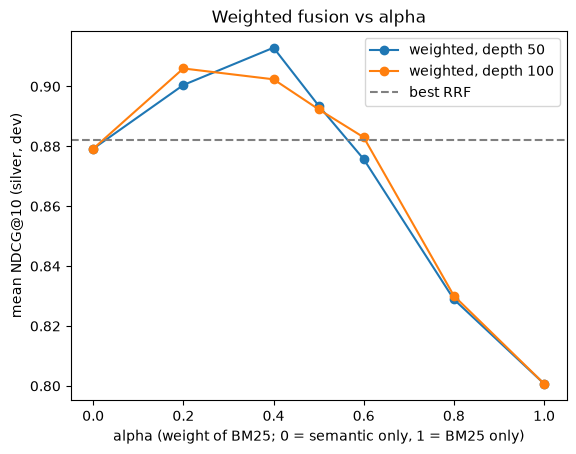

In [7]:
# No labels yet (Phase 13), so this grid uses the SAME silver labels as the BM25 notebook (09, step 7):
#   grade 2 = collected for that exact slice (domain | framework), grade 1 = same domain, other framework.
# Silver labels come from GitHub keyword search, so they favour BM25: read the top 10 too, don't trust only these.
# Re-run with the real development labels from eval/qrels.csv when they exist. Never the 20 test queries.
SLICE = dict(zip(DEV, [("inventory management", "nestjs"), ("point of sale", "react"), ("school management", "laravel"),
                       ("booking system", "spring-boot"), ("chat application", "flutter")]))

def silver(q):
    dom, fw = SLICE[q]
    g = {}
    for d, sel in zip(ids, corpus["selected_by"]):
        if f"{dom}|{fw}" in sel:
            g[d] = 2
        elif any(s.startswith(dom + "|") for s in sel):
            g[d] = 1
    return g

def ndcg10(ranked, grades):
    gain = [grades.get(d, 0) for d in ranked[:10]]
    dcg = sum((2**g - 1) / np.log2(r + 2) for r, g in enumerate(gain))
    ideal = sorted(grades.values(), reverse=True)[:10]
    return dcg / sum((2**g - 1) / np.log2(r + 2) for r, g in enumerate(ideal))

QRELS = {q: silver(q) for q in DEV}

def mean_ndcg(m):
    return np.mean([ndcg10([h["doc_id"] for h in m.search(q, 10)], QRELS[q]) for q in DEV])

rows = [{"setting": "BM25 alone", "NDCG@10": mean_ndcg(bm25)},
        {"setting": "semantic alone", "NDCG@10": mean_ndcg(semantic)}]
for depth in (50, 100):
    for c in (10, 60):
        rows.append({"setting": f"RRF c={c} depth={depth}",
                     "NDCG@10": mean_ndcg(hybrid.with_params(mode="rrf", c=c, depth=depth))})
    for a in (0.2, 0.4, 0.5, 0.6, 0.8):
        rows.append({"setting": f"weighted a={a} depth={depth}",
                     "NDCG@10": mean_ndcg(hybrid.with_params(mode="weighted", alpha=a, depth=depth))})
grid = pd.DataFrame(rows).sort_values("NDCG@10", ascending=False).reset_index(drop=True)
print(grid.round(4).to_string())

# alpha curve: where does the mix beat both methods alone?
for depth in (50, 100):
    al = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]
    plt.plot(al, [mean_ndcg(hybrid.with_params(mode="weighted", alpha=a, depth=depth)) for a in al],
             marker="o", label=f"weighted, depth {depth}")
plt.axhline(grid.loc[grid.setting.str.startswith("RRF"), "NDCG@10"].max(), ls="--", c="gray", label="best RRF")
plt.xlabel("alpha (weight of BM25; 0 = semantic only, 1 = BM25 only)"); plt.ylabel("mean NDCG@10 (silver, dev)")
plt.legend(); plt.title("Weighted fusion vs alpha"); plt.show()

## 8. Speed, results file, hand in

`measure()` times the build and the queries; `save_results()` writes `eval/results/hybrid.json` in the format the Results sheet imports. The metrics stay empty until Phase 13–14: then Member 6's `evaluate_method(method, split="test")` fills them in and you import the file in the **Results sheet** tab of the team plan, add your observations and download the PDF.

**Check:** `eval/results/hybrid.json` exists; this notebook is committed with its outputs on `dev-hybrid`; `pytest` passes.

In [8]:
# The best setting from step 7, timed and saved.
best = dict(mode="weighted", alpha=0.4, depth=50)   # step 7 winner (= the class defaults)
method = hybrid.with_params(**best)
speed = measure(lambda: HybridRanker(bm25, semantic, **best).fit(corpus, refit=False), DEV)  # components already fitted
speed["build_s"] = round(t_bm25 + t_sem, 2)          # the hybrid's real build = both components' fits
print(speed)
save_results(method, speed)

{'build_s': 278.0, 'query_ms_median': 10.83, 'index_mb': 129.4}


WindowsPath('D:/Projects/Y4/IR/Open-Source-Project-Discovery/backend/eval/results/hybrid.json')

## Extra (optional): Fuse three: add TF-IDF

Add TF-IDF as a third list in RRF. Does a third, similar method help, or does it only repeat BM25?

In [9]:
from discovery.rank.tfidf import TfidfRanker

tfidf = TfidfRanker().fit(corpus)
three = hybrid.with_params(mode="rrf", c=60, extra=[tfidf])
print(f"two-way RRF   NDCG@10 (silver): {mean_ndcg(hybrid.with_params(mode='rrf', c=60)):.4f}")
print(f"three-way RRF NDCG@10 (silver): {mean_ndcg(three):.4f}")
for q in DEV:   # how much does TF-IDF repeat BM25?
    A = {h["doc_id"] for h in bm25.search(q)}; T = {h["doc_id"] for h in tfidf.search(q)}
    print(f"  {q[:42]:42s} | BM25∩TF-IDF top10: {len(A & T)}")

two-way RRF   NDCG@10 (silver): 0.8817


three-way RRF NDCG@10 (silver): 0.8432
  beginner inventory management system nestj | BM25∩TF-IDF top10: 2
  point of sale app with react               | BM25∩TF-IDF top10: 1
  school management system laravel           | BM25∩TF-IDF top10: 3
  hotel booking system spring boot           | BM25∩TF-IDF top10: 5
  simple chat application flutter firebase   | BM25∩TF-IDF top10: 1


## 9. A fairer check (added after tuning, settings frozen)

Step 7 chose the setting **and** scored it on the same 5 development queries, so its 0.913 is optimistic (the best of 16 tries on 5 queries). Two checks give a fairer number before the real labels exist:

1. **Leave one query out:** choose the setting on 4 development queries, score it on the 5th, rotate. This scores the *tuning procedure*, not one lucky pick.
2. **Queries we never tuned on:** the drafted queries in `eval/queries.json` (longer, realistic wording), scored **once** with the frozen setting, for **all five methods** with the same silver labels. Nothing was changed after seeing these numbers.

Silver labels are still a stand-in (they come from GitHub keyword search and are lenient). The official number stays the 20 test queries with the Phase 13 labels.


In [10]:
# 9.1 Leave one query out over the step 7 grid
SETTINGS = ([dict(mode="rrf", c=c, depth=d) for d in (50, 100) for c in (10, 60)]
            + [dict(mode="weighted", alpha=a, depth=d) for d in (50, 100) for a in (0.2, 0.4, 0.5, 0.6, 0.8)])
label = lambda s: f"{s['mode']} " + (f"a={s['alpha']}" if s["mode"] == "weighted" else f"c={s['c']}") + f" depth={s['depth']}"
grid_q = {i: [ndcg10([h["doc_id"] for h in hybrid.with_params(**s).search(q, 10)], QRELS[q]) for q in DEV]
          for i, s in enumerate(SETTINGS)}

rows = []
for j, q in enumerate(DEV):
    train = [t for t in range(len(DEV)) if t != j]
    best_i = max(grid_q, key=lambda i: np.mean([grid_q[i][t] for t in train]))
    rows.append({"held-out query": q[:42], "chosen on the other 4": label(SETTINGS[best_i]),
                 "hybrid NDCG@10": grid_q[best_i][j],
                 "BM25 alone": ndcg10([h["doc_id"] for h in bm25.search(q, 10)], QRELS[q]),
                 "semantic alone": ndcg10([h["doc_id"] for h in semantic.search(q, 10)], QRELS[q])})
loo = pd.DataFrame(rows)
print(loo.round(4).to_string(index=False))
print(f"\nleave-one-out mean NDCG@10: hybrid {loo['hybrid NDCG@10'].mean():.4f} | BM25 {loo['BM25 alone'].mean():.4f}"
      f" | semantic {loo['semantic alone'].mean():.4f} | in-sample best (step 7) {grid.loc[0, 'NDCG@10']:.4f}")

                            held-out query    chosen on the other 4  hybrid NDCG@10  BM25 alone  semantic alone
beginner inventory management system nestj weighted a=0.2 depth=100          0.8391      0.7494          0.7652
              point of sale app with react  weighted a=0.4 depth=50          0.7144      0.5500          0.7238
          school management system laravel  weighted a=0.4 depth=50          1.0000      1.0000          1.0000
          hotel booking system spring boot  weighted a=0.4 depth=50          1.0000      0.7968          1.0000
  simple chat application flutter firebase weighted a=0.2 depth=100          0.9008      0.9074          0.9069

leave-one-out mean NDCG@10: hybrid 0.8909 | BM25 0.8007 | semantic 0.8792 | in-sample best (step 7) 0.9129


In [11]:
# 9.2 The drafted queries we never tuned on: every method, the same silver labels, scored once
from discovery.index.boolean import BooleanSearch

QUERIES = {r["id"]: r["query"] for r in json.loads((PATHS["eval"] / "queries.json").read_text())}
# qid: (collection domain, slice frameworks the query names, language the query names)
HELD = {"q01": ("inventory management", ["nestjs"], None), "q02": ("point of sale", ["react", "express"], None),
        "q03": ("school management", ["laravel"], None),   "q04": ("chat application", [], None),
        "q05": ("e-commerce", ["django"], None),           "q06": ("booking system", ["spring-boot"], None),
        "q07": ("blog", ["nextjs"], None),                 "q08": ("hospital management", [], None),
        "q10": ("library management", [], "Java")}
# q09 (REST API boilerplate in FastAPI) has no collection domain, so no silver labels: left out.
# q04 and q08 name no framework we sliced on, so every repository of the domain is grade 2 (lenient).

def silver_held(dom, fws, lang):
    g = {}
    for d, sel, lng in zip(ids, corpus["selected_by"], corpus["language"]):
        if not any(s.startswith(dom + "|") for s in sel):
            continue
        exact = (not fws or any(f"{dom}|{f}" in sel for f in fws)) and (lang is None or lng == lang)
        g[d] = 2 if exact else 1
    return g

HQRELS = {qid: silver_held(*v) for qid, v in HELD.items()}
boolean = BooleanSearch().fit(corpus)
RUNS = {"boolean": boolean, "tfidf": tfidf, "bm25": bm25, "semantic": semantic,
        "hybrid weighted a=0.4 (tuned)": method, "hybrid RRF c=60": hybrid.with_params(mode="rrf", c=60, depth=100)}
ranked = {n: {qid: [h["doc_id"] for h in m.search(QUERIES[qid], 10)] for qid in HELD} for n, m in RUNS.items()}
# Recall and MAP against the POOL (union of every method's top 10), as eval/README.md defines them
pool_rel = {qid: {d for n in ranked for d in ranked[n][qid] if HQRELS[qid].get(d, 0) >= 1} for qid in HELD}

def scores(r, grades, pool):
    rel = [grades.get(d, 0) >= 1 for d in r[:10]]
    p10, r10 = sum(rel) / 10, (sum(rel) / len(pool) if pool else 0.0)
    ap = sum(sum(rel[:i + 1]) / (i + 1) for i, x in enumerate(rel) if x) / len(pool) if pool else 0.0
    return {"P@5": sum(rel[:5]) / 5, "P@10": p10, "R@10": r10, "F1@10": 2 * p10 * r10 / (p10 + r10) if p10 + r10 else 0.0,
            "MAP": ap, "NDCG@10": ndcg10(r, grades)}

per_q = {n: {qid: scores(ranked[n][qid], HQRELS[qid], pool_rel[qid]) for qid in HELD} for n in RUNS}
held = pd.DataFrame({n: pd.DataFrame(per_q[n]).T.mean() for n in RUNS}).T.sort_values("NDCG@10", ascending=False)
print(f"{len(HELD)} never-tuned queries, silver labels\n")
print(held.round(4).to_string())

ndcg_q = pd.DataFrame({n: {qid: per_q[n][qid]["NDCG@10"] for qid in HELD} for n in RUNS})
H = "hybrid weighted a=0.4 (tuned)"
for other in ("bm25", "semantic"):
    d = ndcg_q[H] - ndcg_q[other]
    print(f"hybrid vs {other:8s}: better on {(d > 1e-9).sum()}, equal on {(d.abs() <= 1e-9).sum()}, worse on {(d < -1e-9).sum()} of {len(d)} queries")
print("\nNDCG@10 per query")
print(ndcg_q.round(3).to_string())

9 never-tuned queries, silver labels

                                  P@5    P@10    R@10   F1@10     MAP  NDCG@10
hybrid RRF c=60                0.8444  0.8333  0.3603  0.4971  0.3310   0.7987
hybrid weighted a=0.4 (tuned)  0.8889  0.8444  0.3816  0.5185  0.3519   0.7981
semantic                       0.8444  0.8222  0.3743  0.5073  0.3373   0.7388
bm25                           0.8222  0.8000  0.3428  0.4745  0.3034   0.7136
tfidf                          0.8222  0.7889  0.3419  0.4711  0.2925   0.5996
boolean                        0.5556  0.4889  0.2108  0.2905  0.1742   0.4016
hybrid vs bm25    : better on 6, equal on 1, worse on 2 of 9 queries
hybrid vs semantic: better on 6, equal on 1, worse on 2 of 9 queries

NDCG@10 per query
     boolean  tfidf   bm25  semantic  hybrid weighted a=0.4 (tuned)  hybrid RRF c=60
q01    0.237  0.464  0.638     0.761                          0.910            0.956
q02    0.073  0.408  0.750     0.463                          0.572            0.7

In [12]:
# 9.3 Save: the official metrics stay empty (20 test queries, Phase 13 labels). The fair check goes
# into "preliminary" (as semantic.json does), and a sheet-ready copy for a PRELIMINARY Results sheet.
pq = [{"qid": qid, "query": QUERIES[qid], **{k: round(v, 4) for k, v in per_q[H][qid].items()}} for qid in HELD]
tech = [qid for qid, v in HELD.items() if v[1] or v[2]]
prelim = {
    "label_source": "silver: GitHub collection slices (grade 2 exact slice, 1 same domain)",
    "dev_in_sample": {"query_count": 5, "NDCG@10": round(float(grid.loc[0, "NDCG@10"]), 4),
                      "note": "best of 16 settings, chosen and scored on the same 5 queries (optimistic)"},
    "dev_leave_one_out": {"query_count": 5, "NDCG@10": round(float(loo["hybrid NDCG@10"].mean()), 4),
                          "chosen": loo["chosen on the other 4"].tolist()},
    "held_out_drafted": {"query_ids": list(HELD), "metrics": {k: round(float(v), 4) for k, v in held.loc[H].items()},
                         "all_methods": {n: {k: round(float(v), 4) for k, v in row.items()} for n, row in held.iterrows()},
                         "per_query": pq},
}
path = save_results(method, speed)
res = json.loads(path.read_text()); res["preliminary"] = prelim; path.write_text(json.dumps(res, indent=2))

sheet = {"method": "hybrid", "params": {"mode": "weighted", "alpha": 0.4, "depth": 50, "lexical": "bm25 k1=1.5 b=0.75",
                                        "semantic": "all-MiniLM-L6-v2", "labels": "PRELIMINARY silver, 9 drafted queries"},
         "metrics": prelim["held_out_drafted"]["metrics"],
         "groups": {"paraphrased": {"NDCG@10": None},
                    "technology": {"NDCG@10": round(float(np.mean([per_q[H][q]["NDCG@10"] for q in tech])), 4)}},
         "speed": speed, "per_query": pq}
sheet_path = PATHS["eval"] / "results" / "hybrid-preliminary-sheet.json"
sheet_path.write_text(json.dumps(sheet, indent=2))
print(path, "\n", sheet_path)

D:\Projects\Y4\IR\Open-Source-Project-Discovery\backend\eval\results\hybrid.json 
 D:\Projects\Y4\IR\Open-Source-Project-Discovery\backend\eval\results\hybrid-preliminary-sheet.json


## What we found

- **Build:** nothing of its own; it reuses BM25 (≈17 s) and semantic (≈220–290 s, embedding 8,223 repositories on CPU). Median query **≈10–12 ms** (both lists of 50, then fusion). Size ≈129 MB pickled with both components.
- **Best setting (5 dev queries, silver labels): weighted fusion, α = 0.4, depth 50 → mean NDCG@10 0.913**, against semantic alone 0.879, BM25 alone 0.801 and the best RRF 0.882. These are now the `HybridRanker` defaults.
- **Fusion beats both inputs for every α from 0.2 to 0.5**, so the gain is not one lucky setting. Leaning on BM25 (α = 0.8) drops to 0.83: semantic carries most of the signal, BM25 adds the exact words.
- **RRF vs weighted:** RRF was only level with semantic alone (0.874–0.882). It throws the score gaps away: BM25's sharp drop after a few exact matches is information that weighted fusion keeps. c and depth barely mattered (±0.008).
- **Three-way RRF with TF-IDF hurt** (0.882 → 0.829): a second word-matching list doubles the lexical vote instead of adding a new view.
- **Bad results share one cause:** no must-match words (bus booking for a hotel query, an aquarium log for inventory).
- **Fair check (step 9).** Leave one query out: **0.891** (vs 0.913 in-sample), so the tuning is not overfitting; the setting chosen on 4 queries was always weighted with α 0.2–0.4. On the **9 drafted queries never used for tuning**, all methods with the same silver labels: **hybrid weighted 0.798, hybrid RRF 0.799, semantic 0.739, BM25 0.714, TF-IDF 0.600, Boolean 0.402** (NDCG@10). Hybrid beats BM25 on 6 of 9 queries and semantic on 6 of 9 (1 tie, 2 losses each).
- **Weighted vs RRF is a tie on unseen queries** (0.798 vs 0.799): the dev-set edge of weighted did not carry over. The safe claim is "fusion beats each single method", not "weighted beats RRF".
- **Caveats:** 0.913 is optimistic. The setting was chosen and scored on the same 5 queries, and the silver labels are lenient (bus booking counts as relevant for the hotel query because it was collected under *booking system | spring-boot*). The real number is the 20 test queries with the Phase 13 labels; re-run step 7 with the development labels when they exist.
